# GDELT Events — Preliminary Validation and EDA

## 0. Setup

In [ ]:
!pip -q install duckdb pyarrow

from pathlib import Path
import glob
import os
import shutil

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from IPython.display import display
from google.colab import drive

SEED = 42
MEMORY_LIMIT = '3GB'
THREADS = 2

plt.rcParams.update({
    'figure.dpi': 115,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
})

def human_number(x, pos=None):
    if abs(x) >= 1_000_000:
        return f'{x / 1_000_000:.1f}M'
    if abs(x) >= 1_000:
        return f'{x / 1_000:.0f}K'
    return f'{x:.0f}'

HUMAN = mtick.FuncFormatter(human_number)

drive.mount('/content/drive')

ROOT_CANDIDATES = [
    Path('/content/drive/MyDrive/Data-GDELT'),
    Path('/content/drive/MyDrive/eas587/Data-GDELT'),
]
DATA_ROOT = next((p for p in ROOT_CANDIDATES if p.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Could not find Data-GDELT in MyDrive. Update ROOT_CANDIDATES.')

TMP_DIR = Path('/content/duckdb_tmp')
TMP_DIR.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute(f"SET memory_limit='{MEMORY_LIMIT}'")
con.execute(f"SET threads={THREADS}")
con.execute(f"SET temp_directory='{TMP_DIR}'")
con.execute("SET preserve_insertion_order=false")

print('Drive root:', DATA_ROOT)
print('DuckDB memory limit:', MEMORY_LIMIT)
print('Local free disk:', f"{shutil.disk_usage('/content').free / 1e9:.1f} GB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive root: /content/drive/MyDrive/eas587/Data-GDELT
DuckDB memory limit: 3GB
Local free disk: 93.6 GB


In [ ]:
def q(name):
    return '"' + name.replace('"', '""') + '"'


def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"


def raw_profile(columns):
    expressions = []
    for c in columns:
        col = q(c)
        expressions.extend([
            f"SUM(CASE WHEN {col} IS NULL THEN 1 ELSE 0 END) AS {q(c + '__null')}",
            f"SUM(CASE WHEN {col} IS NOT NULL AND TRIM({col}) = '' THEN 1 ELSE 0 END) AS {q(c + '__empty')}",
            f"APPROX_COUNT_DISTINCT(NULLIF(TRIM({col}), '')) AS {q(c + '__unique')}",
        ])

    row = con.execute(
        'SELECT COUNT(*) AS rows, ' + ', '.join(expressions) + ' FROM raw'
    ).fetchdf().iloc[0]

    total = int(row['rows'])
    records = []
    for c in columns:
        nulls = int(row[f'{c}__null'])
        empty = int(row[f'{c}__empty'])
        records.append({
            'column': c,
            'null_count': nulls,
            'empty_count': empty,
            'missing_or_empty_pct': 100 * (nulls + empty) / total if total else 0,
            'approx_unique': int(row[f'{c}__unique']),
        })

    return total, pd.DataFrame(records)


def plot_missing_profile(profile, title):
    p = profile.sort_values('missing_or_empty_pct')
    fig, ax = plt.subplots(figsize=(9, max(3.6, 0.34 * len(p))))
    ax.barh(p['column'], p['missing_or_empty_pct'])
    ax.set_xlabel('Null or empty fields (%)')
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()


def numeric_validation(specs):
    expressions = []
    for c, spec in specs.items():
        dtype = spec['dtype']
        low = spec.get('low')
        high = spec.get('high')
        col = q(c)
        parsed = f"TRY_CAST(NULLIF(TRIM({col}), '') AS {dtype})"
        nonempty = f"{col} IS NOT NULL AND TRIM({col}) <> ''"

        expressions.extend([
            f"SUM(CASE WHEN {nonempty} AND {parsed} IS NULL THEN 1 ELSE 0 END) AS {q(c + '__parse_fail')}",
            f"SUM(CASE WHEN {parsed} = 0 THEN 1 ELSE 0 END) AS {q(c + '__zero')}",
            f"MIN({parsed}) AS {q(c + '__min')}",
            f"MAX({parsed}) AS {q(c + '__max')}",
        ])

        if low is not None and high is not None:
            expressions.append(
                f"SUM(CASE WHEN {parsed} IS NOT NULL AND ({parsed} < {low} OR {parsed} > {high}) THEN 1 ELSE 0 END) "
                f"AS {q(c + '__out_of_range')}"
            )
        else:
            expressions.append(f"0 AS {q(c + '__out_of_range')}")

    row = con.execute('SELECT ' + ', '.join(expressions) + ' FROM raw').fetchdf().iloc[0]
    records = []
    for c in specs:
        records.append({
            'column': c,
            'parse_failures': int(row[f'{c}__parse_fail']),
            'zeros': int(row[f'{c}__zero']),
            'min': row[f'{c}__min'],
            'max': row[f'{c}__max'],
            'out_of_range': int(row[f'{c}__out_of_range']),
        })
    return pd.DataFrame(records)


def timestamp_validation(column, fmt):
    col = q(column)
    parsed = f"TRY_STRPTIME(NULLIF(TRIM({col}), ''), '{fmt}')"
    nonempty = f"{col} IS NOT NULL AND TRIM({col}) <> ''"
    return con.execute(f'''
        SELECT
            SUM(CASE WHEN {nonempty} AND {parsed} IS NULL THEN 1 ELSE 0 END) AS parse_failures,
            MIN({parsed}) AS min_time,
            MAX({parsed}) AS max_time
        FROM raw
    ''').fetchdf()


def time_coverage(column, fmt, title):
    col = q(column)
    parsed = f"TRY_STRPTIME(NULLIF(TRIM({col}), ''), '{fmt}')"

    daily = con.execute(f'''
        WITH valid AS (
            SELECT {parsed} AS ts
            FROM raw
            WHERE {parsed} IS NOT NULL
        )
        SELECT
            CAST(ts AS DATE) AS date,
            COUNT(*) AS records,
            COUNT(DISTINCT ts) AS slots_seen
        FROM valid
        GROUP BY 1
        ORDER BY 1
    ''').fetchdf()

    daily['date'] = pd.to_datetime(daily['date'])
    expected_dates = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
    missing_dates = expected_dates.difference(pd.DatetimeIndex(daily['date']))
    partial = daily[daily['slots_seen'] < 96].copy()

    full_days = daily[daily['slots_seen'] == 96]
    baseline = full_days['records'].median() if len(full_days) else daily['records'].median()
    peak = daily.loc[daily['records'].idxmax()]

    print('Missing calendar dates:', len(missing_dates))
    if len(missing_dates):
        display(pd.DataFrame({'missing_date': missing_dates}))
    print('Dates with fewer than 96 observed 15-minute timestamps:', len(partial))
    if len(partial):
        display(partial)
    print(
        'Peak day:', peak['date'].date(),
        f"({int(peak['records']):,} records; {peak['records'] / baseline:.2f}x median full-day volume)"
    )

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(daily['date'], daily['records'], marker='o', linewidth=1.5)
    if len(daily) >= 7:
        ax.plot(daily['date'], daily['records'].rolling(7, min_periods=3).mean(), linewidth=2, label='7-day average')
        ax.legend(frameon=False)
    ax.set_ylabel('Records')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(HUMAN)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    files = con.execute(f'''
        WITH valid AS (
            SELECT source_file, {parsed} AS ts
            FROM raw
            WHERE {parsed} IS NOT NULL
        )
        SELECT
            source_file,
            MIN(ts) AS start_time,
            MAX(ts) AS end_time,
            COUNT(*) AS records,
            COUNT(DISTINCT ts) AS slots_seen
        FROM valid
        GROUP BY 1
        ORDER BY start_time
    ''').fetchdf()

    files['file'] = files['source_file'].map(lambda x: '/'.join(Path(x).parts[-2:]))
    display(files[['file', 'start_time', 'end_time', 'records', 'slots_seen']])

    overlaps = []
    for i in range(len(files)):
        for j in range(i + 1, len(files)):
            start = max(files.loc[i, 'start_time'], files.loc[j, 'start_time'])
            end = min(files.loc[i, 'end_time'], files.loc[j, 'end_time'])
            if pd.notna(start) and pd.notna(end) and start <= end:
                overlaps.append({
                    'file_1': files.loc[i, 'file'],
                    'file_2': files.loc[j, 'file'],
                    'overlap_start': start,
                    'overlap_end': end,
                })

    overlap_df = pd.DataFrame(overlaps)
    print('File pairs with overlapping time ranges:', len(overlap_df))
    if len(overlap_df):
        display(overlap_df)

    return daily, files, overlap_df

## 1. Build the local slim Parquet

Only the fields used in preliminary analysis are copied from Drive. The Parquet keeps raw exported values as text and records the source CSV path. No cleaning or row removal happens during this step.

In [ ]:
DATASET_FOLDER = 'Events'
LOCAL_PARQUET = Path('/content/gdelt_events_slim.parquet')
FORCE_REBUILD = False

KEEP_COLUMNS = ['GLOBALEVENTID', 'SQLDATE', 'DATEADDED', 'EventCode', 'EventRootCode', 'QuadClass', 'GoldsteinScale', 'Actor1CountryCode', 'Actor2CountryCode', 'Actor1Type1Code', 'Actor2Type1Code', 'ActionGeo_CountryCode', 'ActionGeo_Lat', 'ActionGeo_Long', 'NumMentions', 'NumSources', 'AvgTone', 'SOURCEURL']
CSV_FILES = sorted(glob.glob(str(DATA_ROOT / DATASET_FOLDER / '**' / '*.csv'), recursive=True))
if not CSV_FILES:
    raise FileNotFoundError(f'No CSV files found under {DATA_ROOT / DATASET_FOLDER}')

header = pd.read_csv(CSV_FILES[0], nrows=0).columns.tolist()
missing_columns = [c for c in KEEP_COLUMNS if c not in header]
if missing_columns:
    raise ValueError(f'Requested columns not found in first CSV: {missing_columns}')

raw_gb = sum(Path(f).stat().st_size for f in CSV_FILES) / 1e9
print(f'CSV files: {len(CSV_FILES)} | raw size: {raw_gb:.2f} GB')

if FORCE_REBUILD or not LOCAL_PARQUET.exists():
    files_sql = '[' + ', '.join(sql_string(f) for f in CSV_FILES) + ']'
    selected = ',\n        '.join(f'CAST({q(c)} AS VARCHAR) AS {q(c)}' for c in KEEP_COLUMNS)
    con.execute(f'''
        COPY (
            SELECT
                {selected},
                filename AS source_file
            FROM read_csv(
                {files_sql},
                header=true,
                all_varchar=true,
                union_by_name=true,
                filename=true
            )
        )
        TO '{LOCAL_PARQUET}'
        (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)
    ''')

print('Local Parquet:', LOCAL_PARQUET)
print('Parquet size:', f"{LOCAL_PARQUET.stat().st_size / 1e9:.2f} GB")

con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM read_parquet('{LOCAL_PARQUET}')")
print('Rows in Parquet:', f"{con.execute('SELECT COUNT(*) FROM raw').fetchone()[0]:,}")

CSV files: 4 | raw size: 1.01 GB


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Local Parquet: /content/gdelt_events_slim.parquet
Parquet size: 0.28 GB
Rows in Parquet: 5,033,644


## 2. Schema, cardinality, missing fields, and empty fields

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 5,033,644


,column,null_count,empty_count,missing_or_empty_pct,approx_unique
0,GLOBALEVENTID,0,0,0.000000,4702203
1,SQLDATE,0,0,0.000000,31
2,DATEADDED,0,0,0.000000,2575
3,EventCode,0,0,0.000000,216
4,EventRootCode,0,0,0.000000,20
5,QuadClass,0,0,0.000000,4
6,GoldsteinScale,14,0,0.000278,35
7,Actor1CountryCode,2364461,0,46.973147,241
8,Actor2CountryCode,2970494,0,59.012795,241
9,Actor1Type1Code,2787399,0,55.375370,36


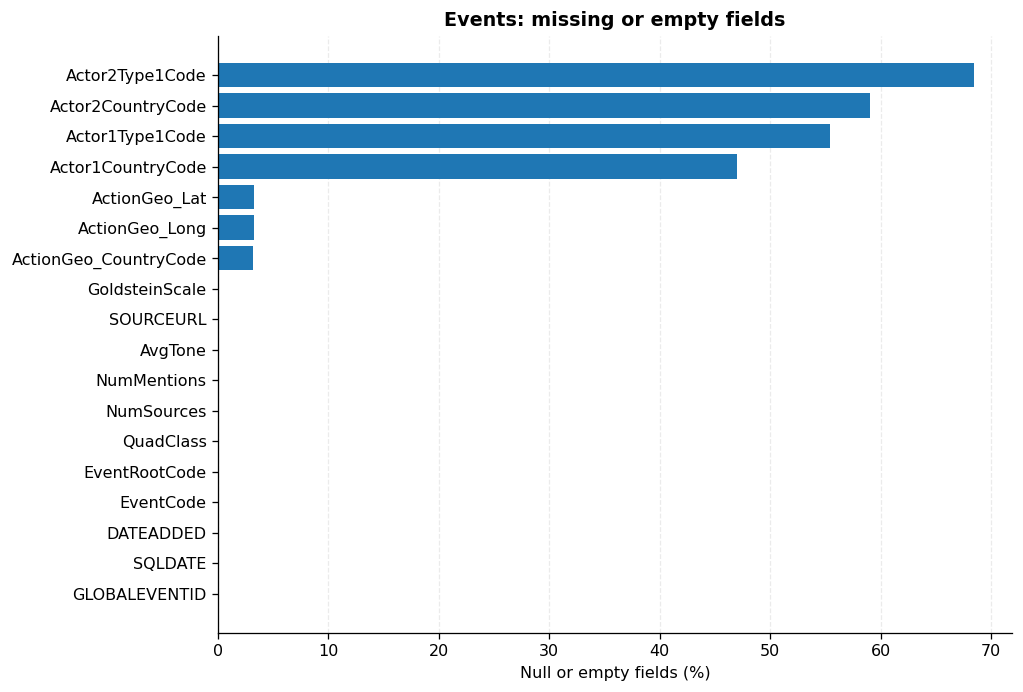

In [ ]:
row_count, events_profile = raw_profile(KEEP_COLUMNS)
print('Rows:', f'{row_count:,}')
display(events_profile)
plot_missing_profile(events_profile, 'Events: missing or empty fields')

Missingness is reported before any parsing. Actor affiliation fields and action geography are kept separate because they describe different concepts. No missing-value imputation is performed in this preliminary notebook.

## 3. Numeric and timestamp parsing validation

In [ ]:
EVENT_NUMERIC = {
    'QuadClass': {'dtype': 'BIGINT', 'low': 1, 'high': 4},
    'GoldsteinScale': {'dtype': 'DOUBLE', 'low': -10, 'high': 10},
    'ActionGeo_Lat': {'dtype': 'DOUBLE', 'low': -90, 'high': 90},
    'ActionGeo_Long': {'dtype': 'DOUBLE', 'low': -180, 'high': 180},
    'NumMentions': {'dtype': 'BIGINT', 'low': 0, 'high': None},
    'NumSources': {'dtype': 'BIGINT', 'low': 0, 'high': None},
    'AvgTone': {'dtype': 'DOUBLE', 'low': -100, 'high': 100},
}

# Use explicit lower-only checks where appropriate.
validation_specs = {
    'QuadClass': {'dtype': 'BIGINT', 'low': 1, 'high': 4},
    'GoldsteinScale': {'dtype': 'DOUBLE', 'low': -10, 'high': 10},
    'ActionGeo_Lat': {'dtype': 'DOUBLE', 'low': -90, 'high': 90},
    'ActionGeo_Long': {'dtype': 'DOUBLE', 'low': -180, 'high': 180},
    'AvgTone': {'dtype': 'DOUBLE', 'low': -100, 'high': 100},
}

display(numeric_validation(validation_specs))

nonnegative = []
for c in ['NumMentions', 'NumSources']:
    result = con.execute(f'''
        SELECT
            SUM(CASE WHEN {q(c)} IS NOT NULL AND TRIM({q(c)}) <> ''
                      AND TRY_CAST(NULLIF(TRIM({q(c)}), '') AS BIGINT) IS NULL THEN 1 ELSE 0 END) AS parse_failures,
            MIN(TRY_CAST(NULLIF(TRIM({q(c)}), '') AS BIGINT)) AS min,
            MAX(TRY_CAST(NULLIF(TRIM({q(c)}), '') AS BIGINT)) AS max,
            SUM(CASE WHEN TRY_CAST(NULLIF(TRIM({q(c)}), '') AS BIGINT) < 0 THEN 1 ELSE 0 END) AS negative_values
        FROM raw
    ''').fetchdf().iloc[0]
    nonnegative.append({'column': c, **result.to_dict()})
display(pd.DataFrame(nonnegative))

print('SQLDATE')
display(timestamp_validation('SQLDATE', '%Y%m%d'))
print('DATEADDED')
display(timestamp_validation('DATEADDED', '%Y%m%d%H%M%S'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column,parse_failures,zeros,min,max,out_of_range
0,QuadClass,0,0,1.000000,4.000000,0
1,GoldsteinScale,0,510045,-10.000000,10.000000,0
2,ActionGeo_Lat,0,1062,-85.622100,85.000000,0
3,ActionGeo_Long,0,249,-179.983000,180.000000,0
4,AvgTone,0,112704,-38.235294,36.666667,0


,column,parse_failures,min,max,negative_values
0,NumMentions,0.0,1.0,714.0,0.0
1,NumSources,0.0,1.0,24.0,0.0


SQLDATE


,parse_failures,min_time,max_time
0,0.0,2026-09-17,2026-10-17


DATEADDED


,parse_failures,min_time,max_time
0,0.0,2026-09-17,2026-10-19 01:30:00


`EventCode` and `EventRootCode` remain text because CAMEO codes may contain leading zeros. Numeric range checks are diagnostics only; unusual values are inspected before any removal decision.

## 4. Unit of analysis and repeated identifiers

In [ ]:
content_columns = [c for c in KEEP_COLUMNS if c != 'GLOBALEVENTID']
signature = "MD5(CONCAT_WS('|', " + ', '.join(
    f"COALESCE({q(c)}, '<NULL>')" for c in content_columns
) + "))"

id_summary = con.execute(f'''
    WITH x AS (
        SELECT
            NULLIF(TRIM(GLOBALEVENTID), '') AS event_id,
            source_file,
            {signature} AS content_signature
        FROM raw
        WHERE NULLIF(TRIM(GLOBALEVENTID), '') IS NOT NULL
    ),
    g AS (
        SELECT
            event_id,
            COUNT(*) AS rows,
            COUNT(DISTINCT source_file) AS files,
            COUNT(DISTINCT content_signature) AS versions
        FROM x
        GROUP BY 1
    )
    SELECT
        COUNT(*) AS distinct_event_ids,
        SUM(CASE WHEN rows > 1 THEN 1 ELSE 0 END) AS repeated_event_ids,
        SUM(CASE WHEN files > 1 THEN 1 ELSE 0 END) AS ids_across_files,
        SUM(CASE WHEN rows > 1 AND versions = 1 THEN 1 ELSE 0 END) AS identical_repeat_groups,
        SUM(CASE WHEN rows > 1 AND versions > 1 THEN 1 ELSE 0 END) AS conflicting_repeat_groups
    FROM g
''').fetchdf()
display(id_summary)

url_summary = con.execute('''
    WITH g AS (
        SELECT
            NULLIF(TRIM(SOURCEURL), '') AS url,
            COUNT(*) AS rows,
            COUNT(DISTINCT NULLIF(TRIM(GLOBALEVENTID), '')) AS event_ids,
            COUNT(DISTINCT source_file) AS files
        FROM raw
        WHERE NULLIF(TRIM(SOURCEURL), '') IS NOT NULL
        GROUP BY 1
    )
    SELECT
        COUNT(*) AS distinct_urls,
        SUM(CASE WHEN rows > 1 THEN 1 ELSE 0 END) AS repeated_urls,
        SUM(CASE WHEN event_ids > 1 THEN 1 ELSE 0 END) AS urls_with_multiple_event_ids,
        SUM(CASE WHEN files > 1 THEN 1 ELSE 0 END) AS urls_across_files,
        MAX(rows) AS max_rows_for_one_url
    FROM g
''').fetchdf()
display(url_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,distinct_event_ids,repeated_event_ids,ids_across_files,identical_repeat_groups,conflicting_repeat_groups
0,5033644,0.0,0.0,0.0,0.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,distinct_urls,repeated_urls,urls_with_multiple_event_ids,urls_across_files,max_rows_for_one_url
0,1439507,878682.0,878682.0,4846.0,475


The intended event-level key is `GLOBALEVENTID`. Repeated `SOURCEURL` values are not automatically duplicates: one article can describe several coded events. Repeated event IDs, especially across source files, are investigated separately.

## 5. Time coverage, daily spikes, partial dates, and file overlap

Missing calendar dates: 0
Dates with fewer than 96 observed 15-minute timestamps: 2


,date,records,slots_seen
31,2026-10-18,1095,93
32,2026-10-19,87,7


Peak day: 2026-09-23 (204,997 records; 1.14x median full-day volume)


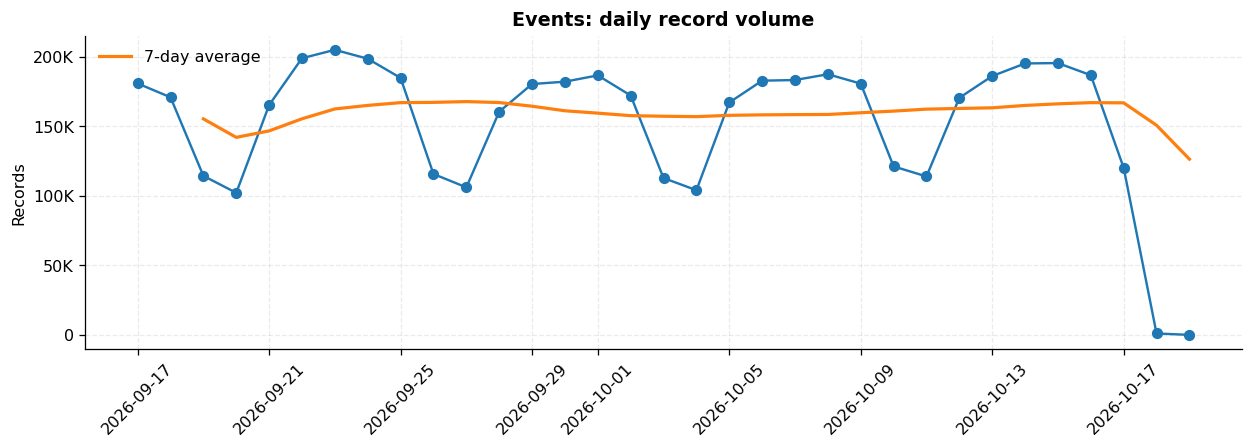

,file,start_time,end_time,records,slots_seen
0,Events_Week1/bq-results-20261019-012723-179237...,2026-09-17,2026-10-19 01:30:00,1342457,1515
1,Events_Week2/bq-results-20261019-012901-179237...,2026-09-25,2026-10-09 23:45:00,1287709,1368
2,Events_Week3/bq-results-20261019-013017-179237...,2026-10-03,2026-10-17 23:00:00,1240138,1385
3,Events_Week4/bq-results-20261019-013132-179237...,2026-10-11,2026-10-19 01:00:00,1163340,767


File pairs with overlapping time ranges: 5


,file_1,file_2,overlap_start,overlap_end
0,Events_Week1/bq-results-20261019-012723-179237...,Events_Week2/bq-results-20261019-012901-179237...,2026-09-25,2026-10-09 23:45:00
1,Events_Week1/bq-results-20261019-012723-179237...,Events_Week3/bq-results-20261019-013017-179237...,2026-10-03,2026-10-17 23:00:00
2,Events_Week1/bq-results-20261019-012723-179237...,Events_Week4/bq-results-20261019-013132-179237...,2026-10-11,2026-10-19 01:00:00
3,Events_Week2/bq-results-20261019-012901-179237...,Events_Week3/bq-results-20261019-013017-179237...,2026-10-03,2026-10-09 23:45:00
4,Events_Week3/bq-results-20261019-013017-179237...,Events_Week4/bq-results-20261019-013132-179237...,2026-10-11,2026-10-17 23:00:00


In [ ]:
event_daily, event_file_ranges, event_overlaps = time_coverage(
    'DATEADDED', '%Y%m%d%H%M%S', 'Events: daily record volume'
)

## 6. Event categories

,quad_class,events,label
0,1,3095898,Verbal cooperation
1,2,579196,Material cooperation
2,3,691582,Verbal conflict
3,4,666968,Material conflict


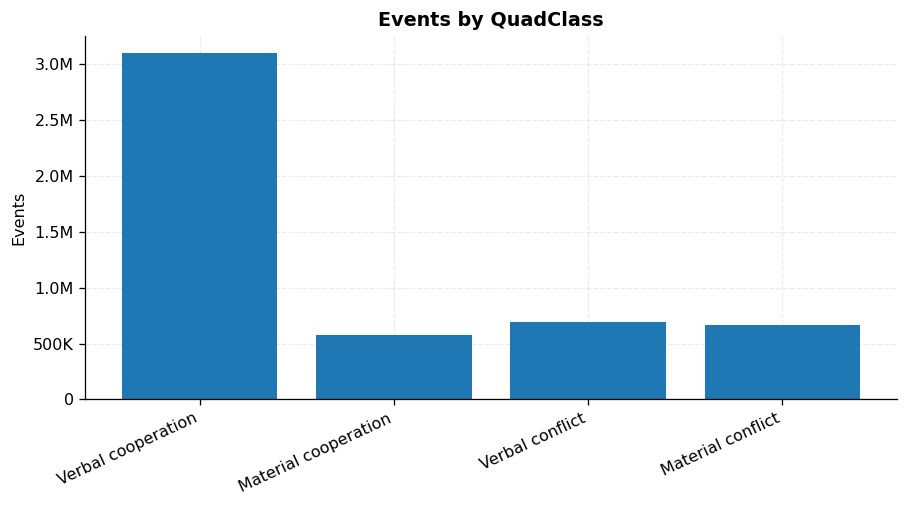

In [ ]:
quad = con.execute('''
    SELECT
        TRY_CAST(NULLIF(TRIM(QuadClass), '') AS BIGINT) AS quad_class,
        COUNT(*) AS events
    FROM raw
    WHERE TRY_CAST(NULLIF(TRIM(QuadClass), '') AS BIGINT) BETWEEN 1 AND 4
    GROUP BY 1
    ORDER BY 1
''').fetchdf()

quad_labels = {
    1: 'Verbal cooperation',
    2: 'Material cooperation',
    3: 'Verbal conflict',
    4: 'Material conflict',
}
quad['label'] = quad['quad_class'].map(quad_labels)
display(quad)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(quad['label'], quad['events'])
ax.set_ylabel('Events')
ax.set_title('Events by QuadClass')
ax.yaxis.set_major_formatter(HUMAN)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

,EventRootCode,events
0,04,1256629
1,01,687924
2,05,446679
3,02,395882
4,11,321311
5,03,308784
6,19,305219
7,17,209850
8,08,171402
9,07,167793


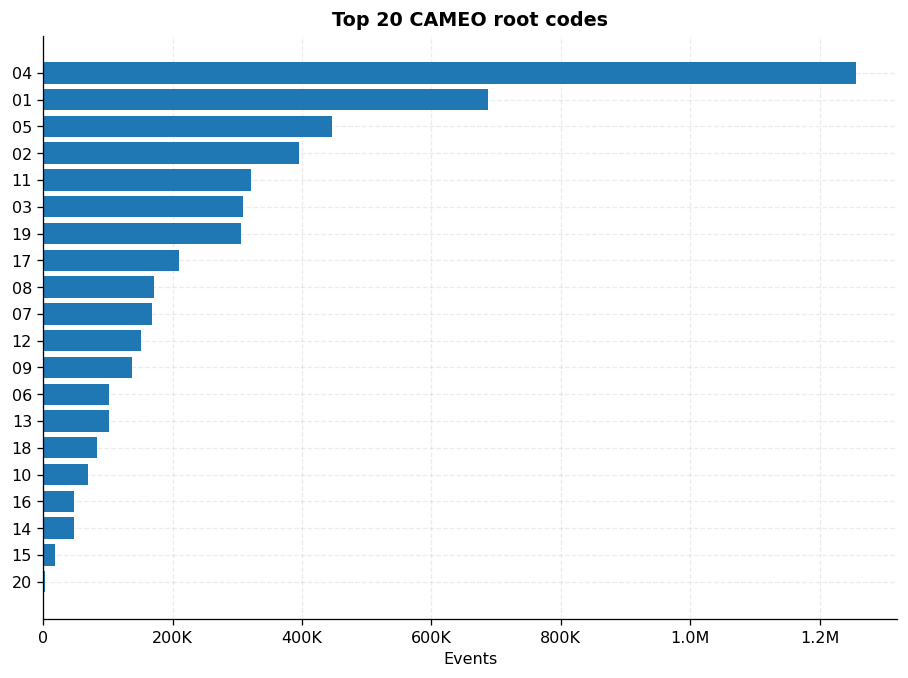

In [ ]:
root_codes = con.execute('''
    SELECT EventRootCode, COUNT(*) AS events
    FROM raw
    WHERE NULLIF(TRIM(EventRootCode), '') IS NOT NULL
    GROUP BY 1
    ORDER BY events DESC
    LIMIT 20
''').fetchdf()
display(root_codes)

fig, ax = plt.subplots(figsize=(8, 6))
plot_df = root_codes.sort_values('events')
ax.barh(plot_df['EventRootCode'], plot_df['events'])
ax.set_xlabel('Events')
ax.set_title('Top 20 CAMEO root codes')
ax.xaxis.set_major_formatter(HUMAN)
plt.tight_layout()
plt.show()

## 7. Numeric distributions and robust summaries

In [ ]:
numeric_summary = con.execute('''
    SELECT
        MEDIAN(TRY_CAST(NULLIF(TRIM(GoldsteinScale), '') AS DOUBLE)) AS goldstein_median,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(GoldsteinScale), '') AS DOUBLE), 0.25) AS goldstein_q1,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(GoldsteinScale), '') AS DOUBLE), 0.75) AS goldstein_q3,
        MEDIAN(TRY_CAST(NULLIF(TRIM(AvgTone), '') AS DOUBLE)) AS tone_median,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(AvgTone), '') AS DOUBLE), 0.25) AS tone_q1,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(AvgTone), '') AS DOUBLE), 0.75) AS tone_q3,
        MEDIAN(TRY_CAST(NULLIF(TRIM(NumMentions), '') AS BIGINT)) AS mentions_median,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(NumMentions), '') AS BIGINT), 0.95) AS mentions_p95,
        MEDIAN(TRY_CAST(NULLIF(TRIM(NumSources), '') AS BIGINT)) AS sources_median,
        QUANTILE_CONT(TRY_CAST(NULLIF(TRIM(NumSources), '') AS BIGINT), 0.95) AS sources_p95
    FROM raw
''').fetchdf()
display(numeric_summary.T.rename(columns={0: 'value'}))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,value
goldstein_median,1.000000
goldstein_q1,-2.000000
goldstein_q3,3.400000
tone_median,-1.785714
tone_q1,-4.450262
tone_q3,0.753891
mentions_median,5.000000
mentions_p95,10.000000
sources_median,1.000000
sources_p95,1.000000


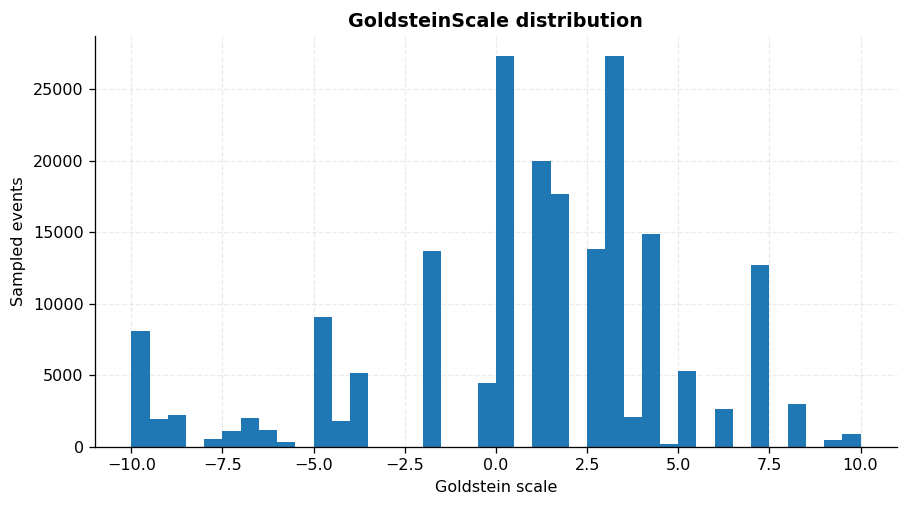

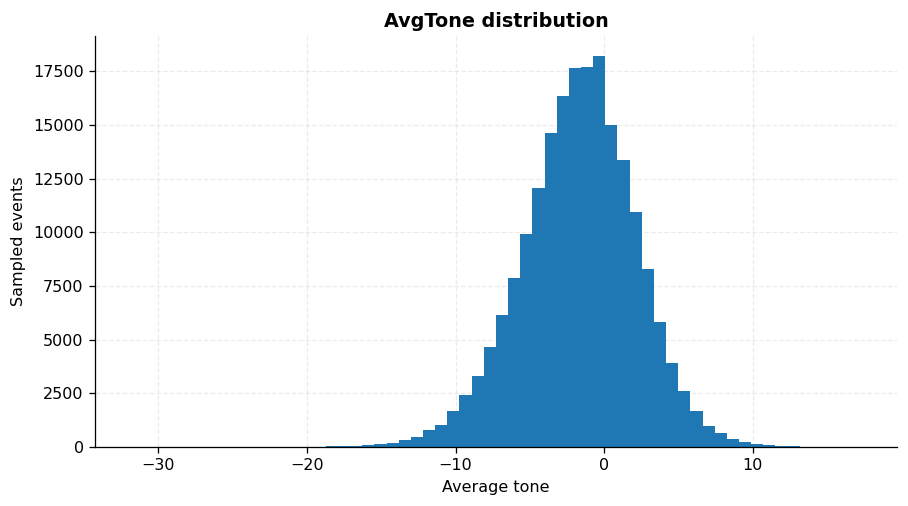

In [ ]:
sample = con.execute('''
    SELECT
        TRY_CAST(NULLIF(TRIM(GoldsteinScale), '') AS DOUBLE) AS GoldsteinScale,
        TRY_CAST(NULLIF(TRIM(AvgTone), '') AS DOUBLE) AS AvgTone,
        TRY_CAST(NULLIF(TRIM(NumMentions), '') AS DOUBLE) AS NumMentions,
        TRY_CAST(NULLIF(TRIM(NumSources), '') AS DOUBLE) AS NumSources,
        TRY_CAST(NULLIF(TRIM(QuadClass), '') AS BIGINT) AS QuadClass
    FROM raw
    WHERE MOD(HASH(COALESCE(GLOBALEVENTID, '')), 1000) < 100
    LIMIT 200000
''').fetchdf()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sample['GoldsteinScale'].dropna(), bins=40)
ax.set_xlabel('Goldstein scale')
ax.set_ylabel('Sampled events')
ax.set_title('GoldsteinScale distribution')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sample['AvgTone'].dropna(), bins=60)
ax.set_xlabel('Average tone')
ax.set_ylabel('Sampled events')
ax.set_title('AvgTone distribution')
plt.tight_layout()
plt.show()

## 8. Geography completeness

In [ ]:
geo = con.execute('''
    SELECT
        COUNT(*) AS rows,
        SUM(CASE WHEN NULLIF(TRIM(ActionGeo_CountryCode), '') IS NULL THEN 1 ELSE 0 END) AS missing_action_country,
        SUM(CASE WHEN NULLIF(TRIM(Actor1CountryCode), '') IS NULL THEN 1 ELSE 0 END) AS missing_actor1_country,
        SUM(CASE WHEN NULLIF(TRIM(Actor2CountryCode), '') IS NULL THEN 1 ELSE 0 END) AS missing_actor2_country,
        SUM(CASE WHEN NULLIF(TRIM(ActionGeo_CountryCode), '') IS NOT NULL
                  AND (NULLIF(TRIM(Actor1CountryCode), '') IS NULL OR NULLIF(TRIM(Actor2CountryCode), '') IS NULL)
                 THEN 1 ELSE 0 END) AS known_location_with_missing_actor_country
    FROM raw
''').fetchdf()
display(geo.T.rename(columns={0: 'count'}))

,count
rows,5033644.0
missing_action_country,158931.0
missing_actor1_country,2364461.0
missing_actor2_country,2970494.0
known_location_with_missing_actor_country,3705962.0


## 9. Relationships among event features

In [ ]:
quad_summary = con.execute('''
    SELECT
        TRY_CAST(NULLIF(TRIM(QuadClass), '') AS BIGINT) AS QuadClass,
        COUNT(*) AS events,
        MEDIAN(TRY_CAST(NULLIF(TRIM(GoldsteinScale), '') AS DOUBLE)) AS median_goldstein,
        MEDIAN(TRY_CAST(NULLIF(TRIM(AvgTone), '') AS DOUBLE)) AS median_tone,
        MEDIAN(TRY_CAST(NULLIF(TRIM(NumMentions), '') AS DOUBLE)) AS median_initial_mentions,
        MEDIAN(TRY_CAST(NULLIF(TRIM(NumSources), '') AS DOUBLE)) AS median_initial_sources
    FROM raw
    WHERE TRY_CAST(NULLIF(TRIM(QuadClass), '') AS BIGINT) BETWEEN 1 AND 4
    GROUP BY 1
    ORDER BY 1
''').fetchdf()
quad_summary['label'] = quad_summary['QuadClass'].map(quad_labels)
display(quad_summary)

corr = sample[['GoldsteinScale', 'AvgTone', 'NumMentions', 'NumSources']].corr(method='spearman')
display(corr.round(3))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,QuadClass,events,median_goldstein,median_tone,median_initial_mentions,median_initial_sources,label
0,1,3095898,2.8,-0.852273,5.0,1.0,Verbal cooperation
1,2,579196,6.4,-1.704545,6.0,1.0,Material cooperation
2,3,691582,-4.0,-3.296703,5.0,1.0,Verbal conflict
3,4,666968,-9.2,-4.724409,5.0,1.0,Material conflict


,GoldsteinScale,AvgTone,NumMentions,NumSources
GoldsteinScale,1.000,0.287,0.007,-0.008
AvgTone,0.287,1.000,0.021,-0.028
NumMentions,0.007,0.021,1.000,0.127
NumSources,-0.008,-0.028,0.127,1.000
